## Initialization

Import python libraries and variable definition

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

## Get data from .txt file and create dataframe

In [2]:
# Create an empty list to store the data
data = []

# Open the text file in read mode
with open('data1.txt', 'r') as file:
    # Skip the first line if it contains headers
    next(file)
    
    # Process each line
    for line in file:
        # Split the line into parts based on tabs
        parts = line.strip().split('\t')

        # Append the extracted data to the list
        data.append(parts)

# Define the column names based on the headers or by assigning names manually
column_names = ["Index", "Phase", "Stiffness", "Depth", "Load", "E", "H", "hc", "Ac", "X", "Y"]

# Create a DataFrame from the list of data with the specified column names
df = pd.DataFrame(data, columns=column_names)

# Convert columns to numeric if needed
df = df.apply(pd.to_numeric, errors='ignore')

# Display the DataFrame
print(df)


       Index  Phase     Stiffness   Depth      Load           E          H  \
0          0      2  40301.593361  29.163  0.194345  220.372934   7.547404   
1          1      2  35389.536065  29.099  0.260810  205.830408  11.458981   
2          2      2  36013.690162  29.105  0.177515  197.756157   6.952057   
3          3      2  39736.701933  29.117  0.219403  221.095724   8.822103   
4          4      2  32196.894285  29.160  0.147034  175.062242   5.645821   
...      ...    ...           ...     ...       ...         ...        ...   
26025  26245      2  37928.684383  29.080  0.156428  204.678570   5.916659   
26026  26246      2  38769.257787  29.165  0.182557  211.438131   7.052510   
26027  26247      2  46773.239762  29.108  0.187835  251.588041   7.058536   
26028  26248      2  36689.951213  29.138  0.178044  200.919047   6.934724   
26029  26249      2  37193.895027  29.137  0.183250  204.026379   7.161883   

           hc     Ac          X          Y  
0      25.547  257

<Axes: xlabel='H', ylabel='E'>

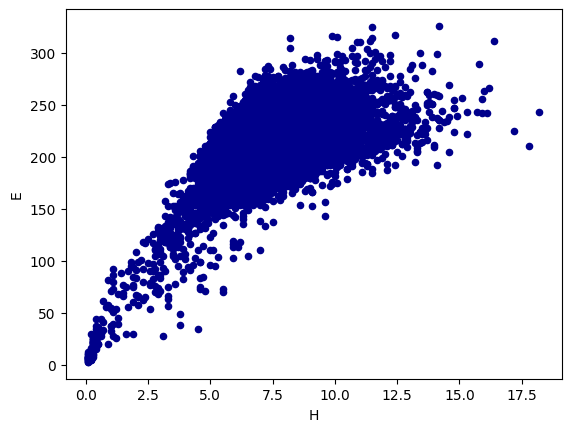

In [3]:
df=df.round(1)
df.plot.scatter(x='H', y='E', c='DarkBlue')

## Plot heat map

           E     H
0      220.4   7.5
1      205.8  11.5
2      197.8   7.0
3      221.1   8.8
4      175.1   5.6
...      ...   ...
26025  204.7   5.9
26026  211.4   7.1
26027  251.6   7.1
26028  200.9   6.9
26029  204.0   7.2

[26030 rows x 2 columns]


<Axes: >

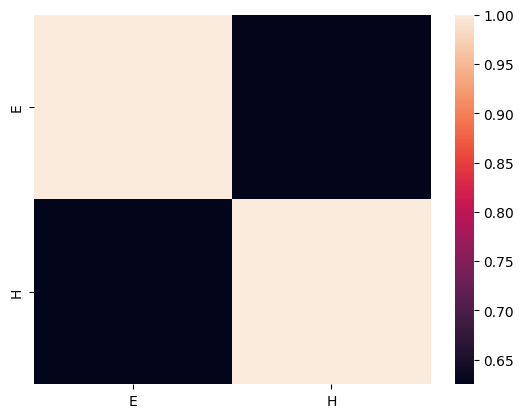

In [4]:
%matplotlib inline

dfMat_E = df[['E', 'H']] #'X coordinate (µm)', 'Y coordinate (µm)', 
print(dfMat_E)

corr = dfMat_E.select_dtypes('number').corr()

# plot the heatmap
sns.heatmap(corr)

Text(50.722222222222214, 0.5, 'Y position (µm)')

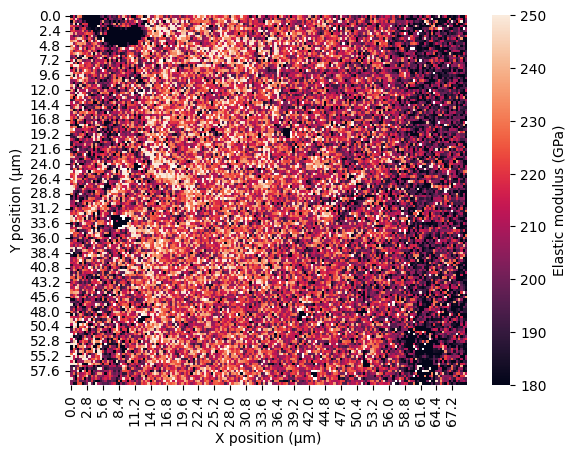

In [5]:
# plot the correlation heatmap
dFMatPivot_E = df.pivot(index="X", columns="Y", values="E")
ax1 = sns.heatmap(dFMatPivot_E,vmin=180,vmax=250,cbar_kws={"label": "Elastic modulus (GPa)"})

# Set axis labels
ax1.set_xlabel('X position (µm)')
ax1.set_ylabel('Y position (µm)')

Text(50.722222222222214, 0.5, 'Y position (µm)')

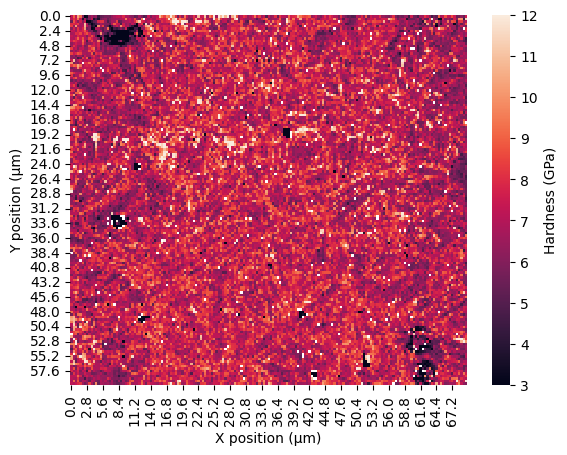

In [6]:
# plot the correlation heatmap
dFMatPivot_H = df.pivot(index="X", columns="Y", values="H")
ax=sns.heatmap(dFMatPivot_H,vmin=3,vmax=12,cbar_kws={"label": "Hardness (GPa)"})

# Set axis labels
ax.set_xlabel('X position (µm)')
ax.set_ylabel('Y position (µm)')

## Histogram plots and Gaussian deconvolution

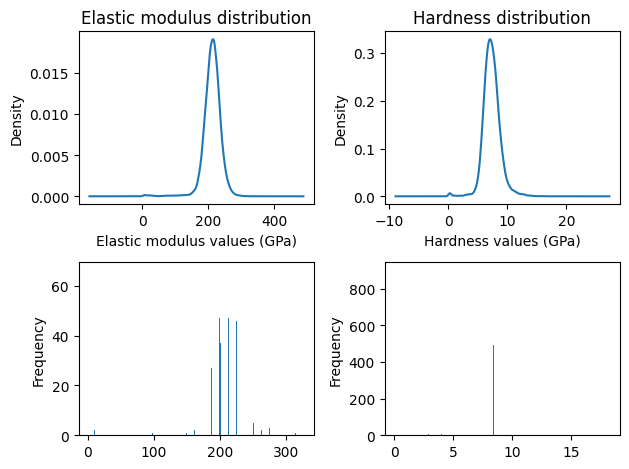

In [7]:
fig = plt.figure()
binsVal=round(df.size/10)

ax1 = fig.add_subplot(221)
ax1 = df['E'].plot.kde()
ax11 = fig.add_subplot(223)
ax11 = df['E'].plot.hist(bins=binsVal)
ax2 = fig.add_subplot(222)
ax2 = df['H'].plot.kde()
ax22 = fig.add_subplot(224)
ax22 = df['H'].plot.hist(bins=binsVal)
ax1.title.set_text('Elastic modulus distribution')
ax1.set_xlabel('Elastic modulus values (GPa)')
ax2.title.set_text('Hardness distribution')
ax2.set_xlabel('Hardness values (GPa)')
plt.tight_layout()
plt.show()

In [8]:
# Extract data from the KDE plot for Elastic modulus
kde_data_em = ax1.get_lines()[0].get_data()
x_values_em = kde_data_em[0]
y_values_em = kde_data_em[1]

# Extract data from the KDE plot for Hardness
kde_data_hardness = ax2.get_lines()[0].get_data()
x_values_hardness = kde_data_hardness[0]
y_values_hardness = kde_data_hardness[1]

# Now you can use x_values_em, y_values_em, x_values_hardness, and y_values_hardness as needed

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_9536\3932012564.py:11: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


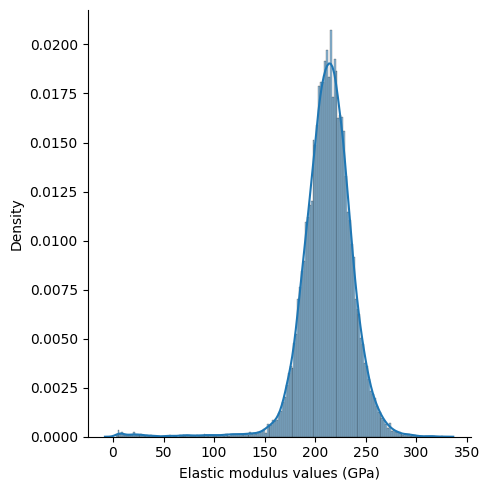

In [9]:
data = norm.rvs(5,0.4,size=1000) # you can use a pandas series or a list if you want

# Define subplots
ax1 = fig.add_subplot(221)
ax1 = sns.displot(df['E'], kde=True,
    stat="density", kde_kws=dict(cut=3))
ax1.set_titles('Elastic modulus distribution')
ax1.set_xlabels('Elastic modulus values (GPa)')
plt.savefig('PDF_E.png', bbox_inches='tight')
plt.savefig('PDF_E.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_9536\3974124005.py:8: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


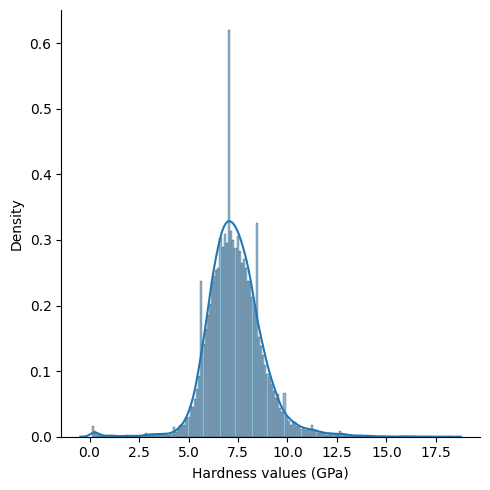

In [10]:
ax2 = fig.add_subplot(222)
ax2 = sns.displot(df['H'], kde=True,
    stat="density", kde_kws=dict(cut=3))
ax2.set_titles('Hardness distribution')
ax2.set_xlabels('Hardness values (GPa)')
plt.savefig('PDF_H.png', bbox_inches='tight')
plt.savefig('PDF_H.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

## K-means clustering analysis

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


[[  6.49719769 186.26235151]
 [  7.41894018 213.3270835 ]
 [  1.97003891  60.24163424]
 [  8.23412387 240.28312689]]


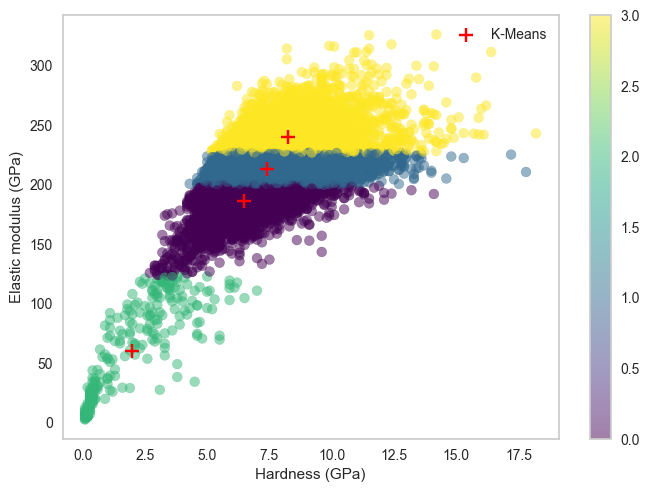

In [19]:
# K-MEANS CLUSTERING
# Importing Modules
from sklearn import datasets
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
numComp = 4
random_stateVal = 42
sizePnt = 50
sizeMean = 100
alphaVal = 0.5
cmapVal = 'viridis'
colorMean = 'red'
markerSym = '+'

dfCluster=df[["H", "E"]]
kmeans = KMeans(n_clusters=numComp, random_state=random_stateVal).fit(dfCluster)
y_pred = kmeans.predict(dfCluster)
centroids = kmeans.cluster_centers_
print(centroids)

# Plot the data points with color-coded clusters
plt.scatter(df['H'], df['E'], c=y_pred, s=sizePnt, alpha=alphaVal, cmap=cmapVal) #kmeans.labels_.astype(float)
plt.colorbar()

# Plot the K-means centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c=colorMean, marker=markerSym, s=sizeMean, label='K-Means')

plt.xlabel('Hardness (GPa)')
plt.ylabel('Elastic modulus (GPa)')
plt.savefig('FastMappingClusters.jpg')
plt.legend(loc='best')
plt.grid(False)
plt.show()

## Elbow Method for Finding the Optimal Number of Clusters in K-Means

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\

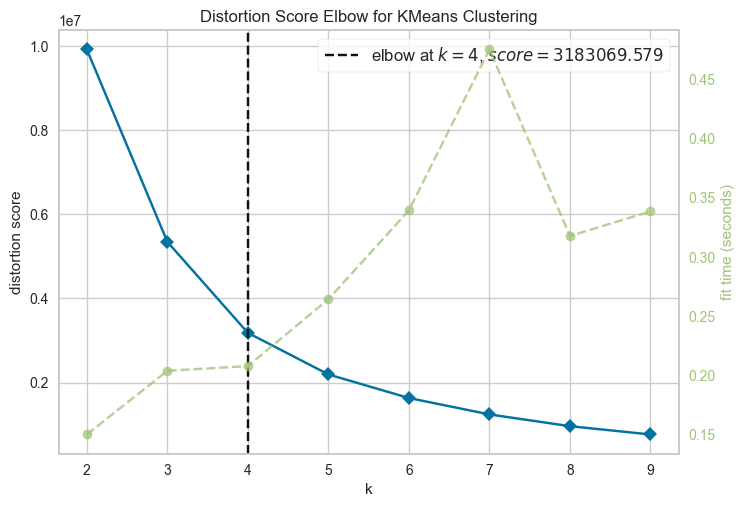

KElbowVisualizer(ax=<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>,
                 estimator=KMeans(n_clusters=9, random_state=5), k=(2, 10))

In [12]:
from sklearn.cluster import KMeans
from yellowbrick.cluster.elbow import kelbow_visualizer

# Extract the columns from the DataFrame
X = dfCluster.values  # Convert the DataFrame to a numpy array

# Use the quick method and immediately show the figure
kelbow_visualizer(KMeans(random_state=5), X, k=(2, 10))

## Gaussian clustering analysis

[[  7.34215902 217.93396439]
 [  8.78635388 229.76170828]
 [  6.55895679 193.41509153]
 [  4.83889229 145.06005817]]


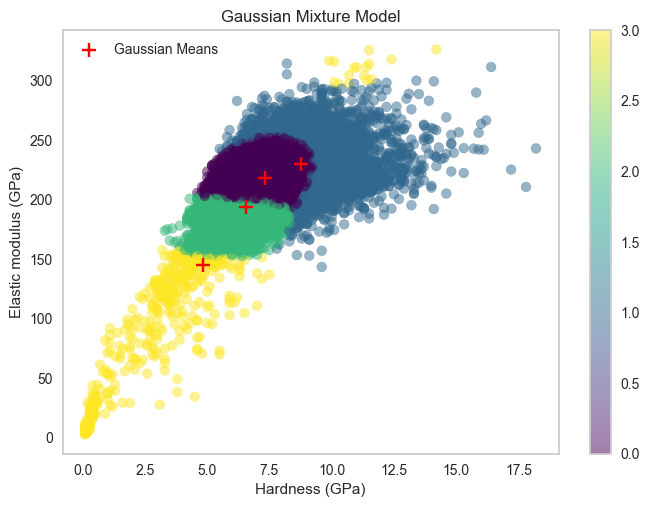

In [20]:
from sklearn.mixture import GaussianMixture

# Create and fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=numComp, random_state=random_stateVal)
gmm.fit(dfCluster)

# Predict cluster assignments for each data point
y_pred = gmm.predict(dfCluster)

# Get the means and covariances of the Gaussian components
means = gmm.means_
print(means)
covariances = gmm.covariances_

# Plot the data points with color-coded clusters
plt.scatter(dfCluster['H'], dfCluster['E'], c=y_pred, s=sizePnt, alpha=alphaVal, cmap=cmapVal)
plt.colorbar()

# Plot the Gaussian component means
plt.scatter(means[:, 0], means[:, 1], c=colorMean, marker=markerSym, s=sizeMean, label='Gaussian Means')

plt.xlabel('Hardness (GPa)')
plt.ylabel('Elastic modulus (GPa)')
plt.title('Gaussian Mixture Model')
plt.legend(loc='best')
plt.grid(False)
plt.savefig('FastMappingClusters_GMM.jpg')
plt.show()

In [14]:
centroids
means

array([[  7.34215902, 217.93396439],
       [  8.78635388, 229.76170828],
       [  6.55895679, 193.41509153],
       [  4.83889229, 145.06005817]])

In [16]:
from sklearn.metrics import silhouette_score

# Calculate Silhouette Score
score1 = silhouette_score(dfCluster, kmeans.labels_)
gmm_labels = gmm.predict(dfCluster)
score2 = silhouette_score(dfCluster, gmm_labels)

print('Silhouete Score for K-means: %.3f' % score1)
print('Silhouete Score for GMM: %.3f' % score2)

Silhouete Score for K-means: 0.511
Silhouete Score for GMM: 0.335


## Import results into the MI database

In [14]:
from datetime import datetime
from GRANTA_MIScriptingToolkit import granta as mpy
import pathlib

mi = mpy.connect('https://nanomecommons.grantami.com/mi_servicelayer',  user_name=usernameVal, password=passwordVal)
db = mi.get_db(db_key="MI_Blank_v2021")
test_table = db.get_table('Indentation statistical data')
folderName = 'Python Demo'

now = datetime.now().strftime("%c")
record_name = 'STK Example :{}'.format(now)
record = test_table.path_from(None, tree_path=['', folderName], end_node=record_name)
record
operatorName = "D. Mercier"

MechPropStr = ['Reduced elastic modulus (mean)', 'Hardness (mean)']

new_file = record.attributes['Other data']
new_pict = record.attributes['Picture']
build_date = record.attributes['Analysis Date']
operator = record.attributes['Operator']
sample_name = record.attributes['Specimen sample name']
E_val = record.attributes[MechPropStr[0]]
H_val = record.attributes[MechPropStr[1]]

new_file

NameError: name 'usernameVal' is not defined

In [ ]:
#Import files and data into MI

file_object = mpy.File()
filename = 'ClusterAnalysis.pdf'
with open(filename, 'rb') as file_buffer:
    file_object.binary_data = file_buffer.read()
file_object.name = filename
file_object.description = 'This is an example file'
new_file.object = file_object
new_file

picture = pathlib.Path('./ClusterAnalysis.png')
new_pict.load(picture)
new_pict

build_date.value = datetime.now()

operator.value = operatorName
sample_name.value = recordName

E_val.value = centroids[0,0]
H_val.value = centroids[0,1]

centroids

record.set_attributes([build_date, new_file, new_pict, operator, sample_name, E_val, H_val])
record = mi.update([record], include_binary_data_in_refresh=True)[0]

#new_pict = record.attributes['Image']
#from IPython.display import Image
#Image(new_pict.value)
#new_pict.save(path='./check.jpg')

In [ ]:
#min-max for each corresponding meta attribute of each mechanical properties
maxminStr = ['Maximum', 'Minimum']

recE = record.attributes[MechPropStr[0]]
funcMax = recE.meta_attributes[maxminStr[0]]
funcMax.value = max(x_values_em)
funcMin = recE.meta_attributes[maxminStr[1]]
funcMin.value = min(x_values_em)
record.set_attributes([recE, funcMax, funcMin])

recH = record.attributes[MechPropStr[1]]
funcMax = recH.meta_attributes[maxminStr[0]]
funcMax.value = max(x_values_hardness)
funcMin = recH.meta_attributes[maxminStr[1]]
funcMin.value = min(x_values_hardness)
record.set_attributes([recH, funcMax, funcMin])

record = mi.update([record])[0]

In [ ]:
#Add probability distribution into the meta attribute of each mechanical properties
recE = record.attributes[MechPropStr[0]]
funcE = recE.meta_attributes['Probability distribution - Reduced elastic modulus']
recH = record.attributes[MechPropStr[1]]
funcH = recH.meta_attributes['Probability distribution - Hardness']
funcH.column_headers

In [ ]:
for xE, yE in zip(x_values_em, y_values_em):
    funcE.add_point({'Young\'s modulus [GPa]': xE, 'y': yE})
funcE.series_linestyles[1] = 'Markers'
#funcE.series_linestyles
#funcE.value
record.set_attributes([funcE])
mi.update([record])

In [ ]:
for xH, yH in zip(x_values_hardness, y_values_hardness):
    funcH.add_point({'Hardness [GPa]': xH, 'y': yH})
funcH.series_linestyles[1] = 'Markers'
#funcH.series_linestyles
#funcH.value
record.set_attributes([funcH])
mi.update([record])

## Add link to the test record

In [ ]:
# Add link into "Indentation statistical data"
new_linked_recs = record.links['Indentation test data']
new_linked_recs.add(Indrecord)
record.set_links('Indentation test data', new_linked_recs)

record = mi.update_links([record])[0]
print(record.links)

# Add link into "Indentation test data"
new_linked_recs = Indrecord.links['Indentation statistical data']
new_linked_recs.add(record)
Indrecord.set_links('Indentation statistical data', new_linked_recs)

Indrecord = mi.update_links([Indrecord])[0]
print(Indrecord.links)

## Change meta attributes of folders and records (color...)

In [ ]:
folder = test_table.path_from(None, tree_path=['', folderName])
folder.color = mpy.RecordColor.White
record.color = mpy.RecordColor.White
mi.update([folder, record])